# Optimisers in Neural Networks
### From Vanilla Gradient Descent to Adam


## Agenda

- Why a plain neural network trained with vanilla gradient descent can be painfully slow
- The idea of smoothing noisy update steps using an Exponential Moving Average
- Gradient Descent with Momentum, and how it speeds up convergence
- RMSprop, and how it tackles oscillation instead of speed
- Adam, which combines the strengths of Momentum and RMSprop
- Learning Rate Decay, and why a shrinking learning rate helps late in training
- A live interactive playground comparing all optimisers on the same loss surface


## The NovaMart Story

NovaMart is a quick-commerce grocery startup. Their delivery-ops team wants to group neighbourhoods into three demand segments — **Light**, **Regular**, and **Heavy** — based on order frequency, basket size, and delivery distance, so that the right number of riders can be assigned to each zone.

A first look at the data shows the three segments twist around each other in a way no straight line can separate. The team decides a deep neural network is needed instead of a simple linear model.

Running alongside this business problem, we will follow a second, smaller story: a NovaMart delivery rider, **Aria**, who has to find the fastest route down a hilly part of the city to reach the delivery hub. Aria's search for the quickest way downhill is a close cousin of what a neural network's optimiser is doing when it searches for the point of lowest loss. We will return to Aria's ride at each new idea.

## Setting Up the NovaMart Segmentation Problem

We simulate a dataset of neighbourhoods with non-linearly separable demand segments (a stand-in for NovaMart's real order data) and prepare it for a neural network.

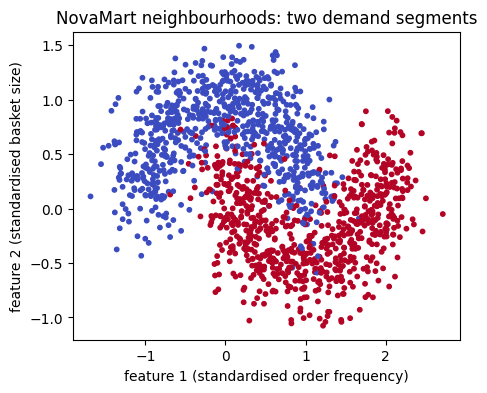

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn as nn

np.random.seed(7)
torch.manual_seed(7)

# Simulated neighbourhood demand data: two engineered features, non-linear boundary
X, y = make_moons(n_samples=1500, noise=0.25, random_state=7)

plt.figure(figsize=(5,4))
plt.scatter(X[:,0], X[:,1], c=y, cmap="coolwarm", s=10)
plt.title("NovaMart neighbourhoods: two demand segments")
plt.xlabel("feature 1 (standardised order frequency)")
plt.ylabel("feature 2 (standardised basket size)")
plt.show()

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=7
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


def build_model():
    model = nn.Sequential(
        nn.Linear(2, 16),
        nn.ReLU(),

        nn.Linear(16, 16),
        nn.ReLU(),

        nn.Linear(16, 1),
        nn.Sigmoid()
    )

    for layer in model:
        if isinstance(layer, nn.Linear):
            nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)

    return model

## Training with Vanilla (Mini-Batch) Gradient Descent

Here $W$ denotes the collection of weights of the network, $b$ the biases, and $L(W,b)$ the loss — a single number telling us how wrong the network's predictions currently are. Vanilla gradient descent updates the weights using:

$$W \leftarrow W - \eta \cdot \frac{\partial L}{\partial W}$$

where $\eta$ (eta) is the **learning rate**, a small positive number controlling how big a step we take, and $\frac{\partial L}{\partial W}$ is the **gradient** — the direction in which the loss increases fastest. We move in the opposite direction to reduce the loss.

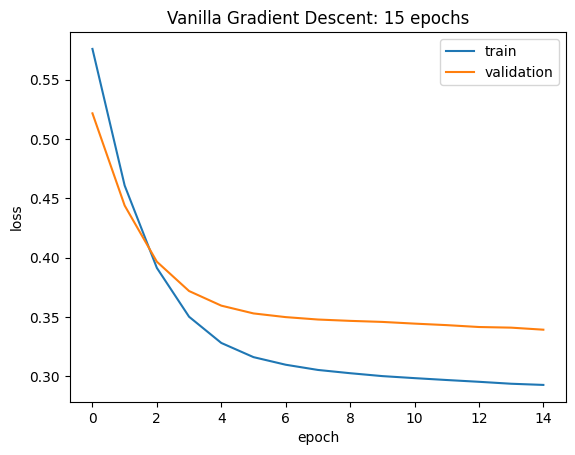

In [ ]:
torch.manual_seed(7)

model_vanilla = build_model()

criterion = nn.BCELoss()
optimizer = torch.optim.SGD(
    model_vanilla.parameters(),
    lr=0.05
)

history_vanilla = {
    "loss": [],
    "val_loss": []
}

X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)

X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

for epoch in range(15): # no. of epochs = 15
    model_vanilla.train()

    permutation = torch.randperm(X_train_tensor.size(0))

    epoch_loss = 0.0

    for i in range(0, X_train_tensor.size(0), 64):
        indices = permutation[i:i + 64]

        X_batch = X_train_tensor[indices]
        y_batch = y_train_tensor[indices]

        optimizer.zero_grad()

        y_pred = model_vanilla(X_batch)
        loss = criterion(y_pred, y_batch)

        loss.backward()
        optimizer.step()

        epoch_loss += loss.item() * len(indices)

    epoch_loss /= X_train_tensor.size(0)

    model_vanilla.eval()

    with torch.no_grad():
        y_val_pred = model_vanilla(X_test_tensor)
        val_loss = criterion(y_val_pred, y_test_tensor).item()

    history_vanilla["loss"].append(epoch_loss)
    history_vanilla["val_loss"].append(val_loss)

plt.plot(history_vanilla["loss"], label="train")
plt.plot(history_vanilla["val_loss"], label="validation")

plt.title("Vanilla Gradient Descent: 15 epochs")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.show()

**Observe:** after 15 epochs the loss is still high and barely moving. If we let this train for a few hundred epochs it does eventually settle — but NovaMart's real order data has millions of rows, and waiting hundreds of epochs is not realistic before every rider-allocation decision.

**Quiz 1**

```
A gradient descent optimiser looks at only one training example before each weight update. What is this variant called?

1. Batch Gradient Descent
2. Stochastic Gradient Descent
3. Mini-Batch Gradient Descent
4. Momentum Gradient Descent
```
**Answer:** 2. Stochastic Gradient Descent

**Explanation:** Batch Gradient Descent uses the entire dataset per update, Mini-Batch uses a small group of examples, and Stochastic Gradient Descent updates the weights after looking at a single example at a time — the noisiest but fastest-to-start variant.

## Why Is Training So Slow?

Picture Aria the delivery rider again. The loss surface is the hill she is riding down, her position is the current weights $W$, and each gradient calculation tells her the steepest direction downhill **from where she is standing right now** — not the best overall route to the hub.

If the hill is shaped like a long, narrow valley (steep on the sides, gently sloping along the floor), Aria's bike keeps swerving from one side of the valley to the other instead of rolling smoothly along the valley floor toward the hub. Each mini-batch of NovaMart data gives the network a slightly different, noisy read of "which way is downhill," so the weights zig-zag the same way Aria's bike does — and that zig-zagging is exactly why so many epochs are needed.

<img src="https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/241/925/original/ChatGPT_Image_Sep_23__2026__03_59_47_PM.png?1790159410" height=500>


**Ask AI**

After class, describe the shape of a loss surface (steep sides, flat floor) to an AI assistant and ask it to explain, in its own words, why gradient descent zig-zags on this kind of surface. Compare its explanation with Aria's story above.

## Smoothing the Ride: Exponential Moving Average

Instead of reacting fully to each new noisy gradient reading, Aria could instead **blend** her current direction with the direction she was already travelling in. This blending idea is called an Exponential Moving Average (EMA):

$$V_t = \beta \cdot V_{t-1} + (1-\beta) \cdot g_t$$

Here $t$ is the current step, $V_t$ is the smoothed direction after step $t$, $V_{t-1}$ is the smoothed direction from the previous step, $g_t$ is the raw (noisy) gradient computed at step $t$, and $\beta$ (beta) is a number between 0 and 1 that controls how much weight is given to past direction versus the newest reading. A $\beta$ close to 1 means Aria trusts her established direction more and reacts less to each bump in the road.

**Quiz 2**


Using $V_t = beta * V_(t-1) + (1 - beta) * g_t$, suppose $V_0$ = 0, beta = 0.8, and the gradient at step 1 is $g_1$ = 0.5. What is $V_1$?

1. 0.10
2. 0.40
3. 0.50
4. 0.90

**Answer:** 1. 0.10

**Explanation:** $V_1$ = 0.8 * 0 + (1 - 0.8) * 0.5 = 0.2 * 0.5 = 0.10.

## Gradient Descent with Momentum

Momentum applies the EMA idea directly to the gradient, then uses the smoothed value to update the weights:

$$V_{dW} = \beta \cdot V_{dW} + (1-\beta) \cdot \frac{\partial L}{\partial W}, \qquad W \leftarrow W - \eta \cdot V_{dW}$$

$V_{dW}$ is the running, smoothed gradient (Aria's blended sense of "downhill"), and everything else is as defined earlier. Just like a bicycle picks up speed rolling downhill and doesn't instantly change direction over every small bump, momentum lets the optimiser build up speed along the valley floor while cancelling out side-to-side swerving.

<img src="https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/241/942/original/ChatGPT_Image_Sep_23__2026__04_12_35_PM.png?1790160168" height=500>

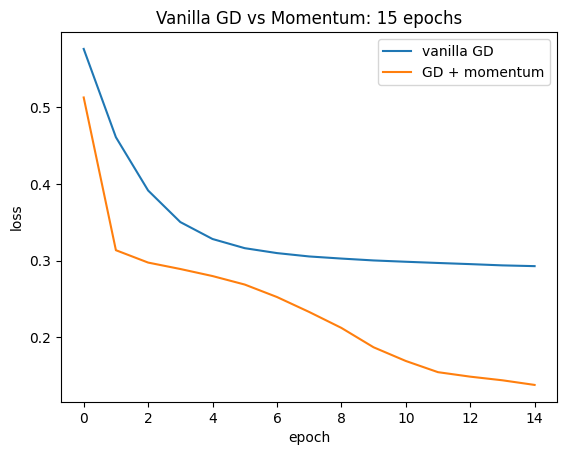

In [ ]:
model_momentum = build_model()

criterion = nn.BCELoss()
optimizer_momentum = torch.optim.SGD(
    model_momentum.parameters(),
    lr=0.05,
    momentum=0.9 # beta
)

history_momentum = {
    "loss": [],
    "val_loss": []
}

X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)

X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

for epoch in range(15):
    model_momentum.train()

    permutation = torch.randperm(X_train_tensor.size(0))
    epoch_loss = 0.0

    for i in range(0, X_train_tensor.size(0), 64):
        indices = permutation[i:i + 64]

        X_batch = X_train_tensor[indices]
        y_batch = y_train_tensor[indices]

        optimizer_momentum.zero_grad()

        y_pred = model_momentum(X_batch)
        loss = criterion(y_pred, y_batch)

        loss.backward()
        optimizer_momentum.step()

        epoch_loss += loss.item() * len(indices)

    epoch_loss /= X_train_tensor.size(0)

    model_momentum.eval()

    with torch.no_grad():
        y_val_pred = model_momentum(X_test_tensor)
        val_loss = criterion(y_val_pred, y_test_tensor).item()

    history_momentum["loss"].append(epoch_loss)
    history_momentum["val_loss"].append(val_loss)

plt.plot(history_vanilla["loss"], label="vanilla GD")
plt.plot(history_momentum["loss"], label="GD + momentum")

plt.title("Vanilla GD vs Momentum: 15 epochs")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.show()

**Observe:** with the same 15 epochs and the same learning rate, momentum reaches a noticeably lower loss than vanilla gradient descent — Aria's bike is now rolling smoothly down the valley floor instead of bouncing between the walls.

## Interactive Playground: Watching the Optimisers Ride the Hill

This is a live demo cell for the instructor. It draws a narrow, valley-shaped loss surface (Aria's hill) and traces the path each optimiser takes from the same starting point. Use the sliders to change the learning rate and momentum/decay factors and see how each path changes in real time.

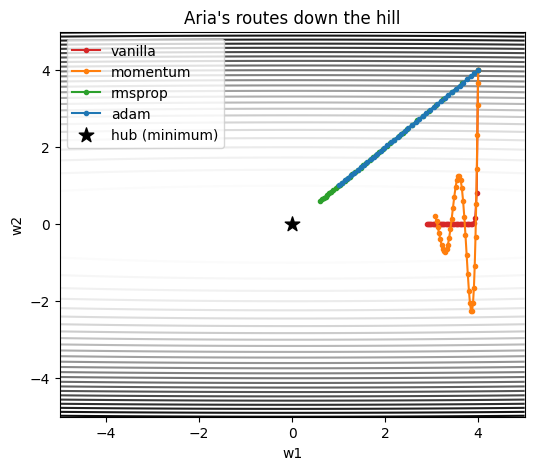

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from ipywidgets import interact, FloatSlider

# A narrow valley-shaped loss surface: steep in one direction, gentle in the other
def loss_surface(w1, w2):
    return 0.05 * w1**2 + 5 * w2**2

def grad_surface(w1, w2):
    return np.array([0.10 * w1, 10 * w2])

def run_optimiser(kind, lr, beta1, beta2, steps=40, start=np.array([4.0, 4.0])):
    w = start.copy()
    v = np.zeros(2)
    s = np.zeros(2)
    eps = 1e-8
    path = [w.copy()]
    for t in range(1, steps + 1):
        g = grad_surface(*w)
        if kind == "vanilla":
            w = w - lr * g
        elif kind == "momentum":
            v = beta1 * v + (1 - beta1) * g
            w = w - lr * v
        elif kind == "rmsprop":
            s = beta2 * s + (1 - beta2) * (g ** 2)
            w = w - lr * g / (np.sqrt(s) + eps)
        elif kind == "adam":
            v = beta1 * v + (1 - beta1) * g
            s = beta2 * s + (1 - beta2) * (g ** 2)
            v_hat = v / (1 - beta1 ** t)
            s_hat = s / (1 - beta2 ** t)
            w = w - lr * v_hat / (np.sqrt(s_hat) + eps)
        path.append(w.copy())
    return np.array(path)

def plot_paths(lr=0.08, beta1=0.9, beta2=0.99):
    w1 = np.linspace(-5, 5, 200)
    w2 = np.linspace(-5, 5, 200)
    W1, W2 = np.meshgrid(w1, w2)
    Z = loss_surface(W1, W2)

    plt.figure(figsize=(6, 5))
    plt.contour(W1, W2, Z, levels=25, cmap="Greys")
    for kind, colour in [("vanilla", "tab:red"), ("momentum", "tab:orange"),
                         ("rmsprop", "tab:green"), ("adam", "tab:blue")]:
        path = run_optimiser(kind, lr, beta1, beta2)
        plt.plot(path[:, 0], path[:, 1], marker=".", color=colour, label=kind)
    plt.scatter([0], [0], color="black", marker="*", s=120, label="hub (minimum)")
    plt.title("Aria's routes down the hill")
    plt.xlabel("w1"); plt.ylabel("w2"); plt.legend()
    plt.show()

interact(
    plot_paths,
    lr=FloatSlider(
        value=0.08,
        min=0.01,
        max=0.20,
        step=0.01,
        description="learning rate",
        style={"description_width": "130px"},
        layout={"width": "350px"}
    ),
    beta1=FloatSlider(
        value=0.9,
        min=0.5,
        max=0.99,
        step=0.01,
        description="beta1 (momentum)",
        style={"description_width": "130px"},
        layout={"width": "350px"}
    ),
    beta2=FloatSlider(
        value=0.99,
        min=0.9,
        max=0.999,
        step=0.001,
        description="beta2 (RMSprop)",
        style={"description_width": "130px"},
        layout={"width": "350px"}
    )
);

**Quiz 3**

```
In the bicycle analogy, what does the momentum term (beta) most closely represent?

1. The steepness of the hill at Aria's current position
2. How much of Aria's previous direction carries over into her next move
3. The total distance to the hub
4. The number of gears on Aria's bike
```
**Answer:** 2. How much of Aria's previous direction carries over into her next move

**Explanation:** Beta weights the previous smoothed direction V_(t-1) in the EMA formula — a higher beta means more of the past direction is retained, just as a rolling bicycle retains momentum from the direction it was already moving in.

## RMSprop

Momentum speeds Aria up, but on a very steep-sided valley she can still overshoot and wobble. RMSprop takes a different approach: instead of smoothing the **direction**, it smooths the **size** of past gradients and uses that to shrink the step in directions that have been consistently steep.

$$S_{dW} = \beta_2 \cdot S_{dW} + (1-\beta_2) \cdot \left(\frac{\partial L}{\partial W}\right)^2, \qquad W \leftarrow W - \eta \cdot \frac{\partial L / \partial W}{\sqrt{S_{dW}} + \epsilon}$$

$S_{dW}$ is the running average of the *squared* gradient (a measure of how large and noisy recent gradients have been), $\beta_2$ is the smoothing factor for this average, and $\epsilon$ (epsilon) is a tiny constant added only to avoid dividing by zero. Dividing by $\sqrt{S_{dW}}$ automatically takes smaller steps on directions that have been consistently steep and larger steps on directions that have been consistently gentle — like Aria automatically braking on the steep cross-slope and pedalling harder along the gentle straight.

<img src="https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/241/947/original/compressed.jpg?1790161037" height=500>

**Quiz 4**

```
For one weight, recent gradients have been large and inconsistent in sign (jumping between positive and negative),
while for a second weight, gradients have been small and steady. What will RMSprop do?

1. Take equally large steps for both weights
2. Take a smaller step for the first weight and a larger step for the second
3. Take a larger step for the first weight and a smaller step for the second
4. Stop updating the first weight entirely
```
**Answer:** 2. Take a smaller step for the first weight and a larger step for the second

**Explanation:** RMSprop divides the step by the square root of the running average of squared gradients. A weight with large, noisy gradients builds up a large S_dW and gets a smaller effective step; a weight with small, steady gradients keeps a small S_dW and gets a comparatively larger step.

## AI Infusion: Spot the Gap

An AI assistant, asked to explain Adam in one line, wrote the following:

> "Adam is the best optimiser because it removes the need to choose a learning rate at all — it figures out the entire step size automatically."

This explanation sounds confident but is not quite right. After class, ask an AI assistant to explain Adam itself, and to specifically check the claim above against the update rule $W \leftarrow W - \eta \cdot \hat{V}_{dW} / (\sqrt{\hat{S}_{dW}} + \epsilon)$. Identify what $\eta$ still does in that formula, and rewrite the one-line explanation so it is accurate. This is a useful habit with any AI-generated technical explanation: treat it as a first draft to verify against the actual formula, not a final answer.

## Adam

Adam (Adaptive Moment Estimation) combines Momentum's smoothed direction $V_{dW}$ with RMSprop's smoothed step-size control $S_{dW}$. Because both $V_{dW}$ and $S_{dW}$ start at zero, they are biased toward zero in the earliest steps, so Adam corrects for this bias before using them:

$$\hat{V}_{dW} = \frac{V_{dW}}{1-\beta_1^{t}}, \qquad \hat{S}_{dW} = \frac{S_{dW}}{1-\beta_2^{t}}, \qquad W \leftarrow W - \eta \cdot \frac{\hat{V}_{dW}}{\sqrt{\hat{S}_{dW}} + \epsilon}$$

$\beta_1$ is the momentum smoothing factor, $\beta_2$ is the RMSprop smoothing factor, $t$ is the current step number, and $\hat{V}_{dW}$, $\hat{S}_{dW}$ are the bias-corrected versions of $V_{dW}$ and $S_{dW}$. Aria now gets both benefits at once: a smoothed sense of direction, and automatic braking on the steep parts of the hill.

<img src="https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/241/953/original/ChatGPT_Image_Sep_23__2026__04_33_10_PM.png?1790161400" height=500>

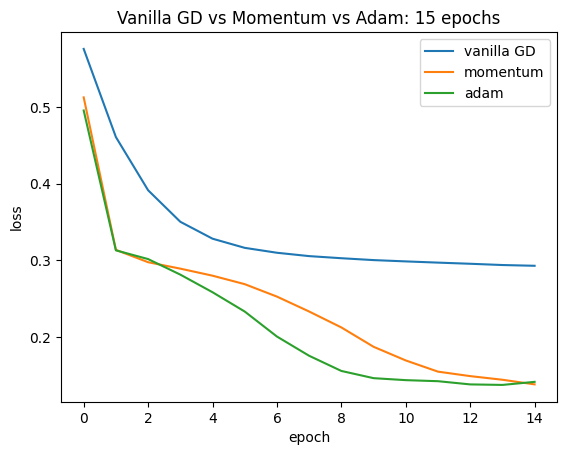

In [ ]:
model_adam = build_model()

criterion = nn.BCELoss()
optimizer_adam = torch.optim.Adam(
    model_adam.parameters(),
    lr=0.01,
    betas=(0.9, 0.999) # beta1 and beta2
)

history_adam = {
    "loss": [],
    "val_loss": []
}

X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)

X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

for epoch in range(15):
    model_adam.train()

    permutation = torch.randperm(X_train_tensor.size(0))
    epoch_loss = 0.0

    for i in range(0, X_train_tensor.size(0), 64):
        indices = permutation[i:i + 64]

        X_batch = X_train_tensor[indices]
        y_batch = y_train_tensor[indices]

        optimizer_adam.zero_grad()

        y_pred = model_adam(X_batch)
        loss = criterion(y_pred, y_batch)

        loss.backward()
        optimizer_adam.step()

        epoch_loss += loss.item() * len(indices)

    epoch_loss /= X_train_tensor.size(0)

    model_adam.eval()

    with torch.no_grad():
        y_val_pred = model_adam(X_test_tensor)
        val_loss = criterion(y_val_pred, y_test_tensor).item()

    history_adam["loss"].append(epoch_loss)
    history_adam["val_loss"].append(val_loss)

plt.plot(history_vanilla["loss"], label="vanilla GD")
plt.plot(history_momentum["loss"], label="momentum")
plt.plot(history_adam["loss"], label="adam")

plt.title("Vanilla GD vs Momentum vs Adam: 15 epochs")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.show()

## Learning Rate Decay

Even with Adam, a fixed learning rate can be too large to settle precisely once training is close to the minimum — Aria is nearly at the hub but her steps are still hub-overshooting size. Learning rate decay shrinks $\eta$ gradually as training progresses:

$$\eta_{\text{epoch}} = \frac{\eta_0}{1 + r_0 \cdot \text{epoch}}$$

$\eta_0$ is the initial learning rate, $\text{epoch}$ is the current epoch number, $r_0$ is the decay rate controlling how quickly $\eta$ shrinks, and $\eta_{\text{epoch}}$ is the resulting, smaller learning rate used at that epoch.

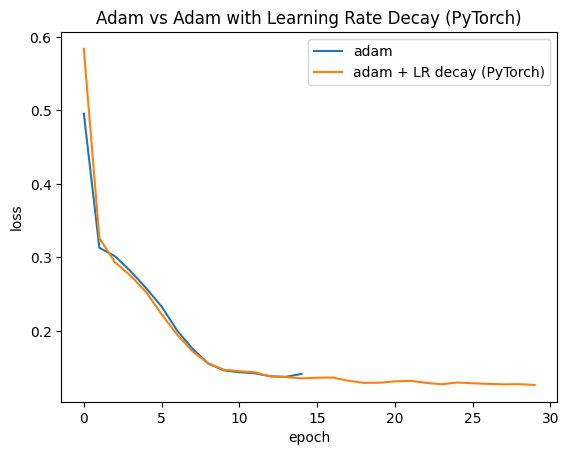

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
# matplotlib.pyplot and numpy are already imported in previous cells and are available.

# 1. PyTorch Model Definition
class NovaMartModel(nn.Module):
    def __init__(self, input_features):
        super(NovaMartModel, self).__init__()
        self.layer1 = nn.Linear(input_features, 16)
        self.relu1 = nn.ReLU()
        self.layer2 = nn.Linear(16, 16)
        self.relu2 = nn.ReLU()
        self.output_layer = nn.Linear(16, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.relu1(self.layer1(x))
        x = self.relu2(self.layer2(x))
        x = self.sigmoid(self.output_layer(x))
        return x

# 2. Data Preparation for PyTorch
# X_train, y_train, X_test, y_test are numpy arrays from previous cells.
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)

batch_size = 64

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

# 3. PyTorch Model Initialization and Training Setup
input_features = X_train.shape[1]
model_adam_decay_torch = NovaMartModel(input_features)

initial_lr = 0.01

optimizer = optim.Adam(
    model_adam_decay_torch.parameters(),
    lr=initial_lr,
    betas=(0.9, 0.999)
)

criterion = nn.BCELoss()

# 4. Learning Rate Scheduler for PyTorch
decay_rate_r0 = 0.05

def pytorch_lr_lambda(epoch):
    # lr_epoch = initial_lr / (1 + r0 * epoch)
    return 1.0 / (1.0 + decay_rate_r0 * epoch)

lr_scheduler = optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda=pytorch_lr_lambda
)

# 5. Training Loop
epochs = 30

history_decay_torch_loss = []
history_decay_torch_val_loss = []

for epoch in range(epochs):

    # Training phase
    model_adam_decay_torch.train()
    running_loss = 0.0

    for inputs, labels in train_loader:
        optimizer.zero_grad()

        outputs = model_adam_decay_torch(inputs)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)

    epoch_train_loss = running_loss / len(train_dataset)
    history_decay_torch_loss.append(epoch_train_loss)

    # Validation phase
    model_adam_decay_torch.eval()
    val_loss = 0.0

    with torch.no_grad():
        for inputs, labels in test_loader:
            outputs = model_adam_decay_torch(inputs)

            loss = criterion(outputs, labels)

            val_loss += loss.item() * inputs.size(0)

    epoch_val_loss = val_loss / len(test_dataset)
    history_decay_torch_val_loss.append(epoch_val_loss)

    # Update learning rate after each epoch
    lr_scheduler.step()

# 6. Plotting Results
plt.plot(history_adam["loss"], label="adam")
plt.plot(
    history_decay_torch_loss,
    label="adam + LR decay (PyTorch)"
)

plt.title("Adam vs Adam with Learning Rate Decay (PyTorch)")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.show()

**Quiz 5**

```
Using eta_epoch = eta_0 / (1 + r0 * epoch), if eta_0 = 0.02, r0 = 0.05, and epoch = 20, what is eta_epoch?

1. 0.005
2. 0.010
3. 0.015
4. 0.020
```
**Answer:** 2. 0.010

**Explanation:** eta_epoch = 0.02 / (1 + 0.05 * 20) = 0.02 / (1 + 1.0) = 0.02 / 2 = 0.010.

### Visual interactive playground to visualise different optimisers
[Follow this link](https://shrijankumar1-maker.github.io/Optimiser-visualiser/)

In [ ]:
from IPython.display import IFrame, display

display(
    IFrame(
        src="https://shrijankumar1-maker.github.io/Optimiser-visualiser/",
        width="100%",
        height=900
    )
)

**Ask AI**

After class, ask an AI assistant to explain one optimiser not covered in depth today — for example Nadam or AdaGrad — and how it builds on the ideas of Momentum and RMSprop you learned in this class.

## Wrap-Up

- Vanilla mini-batch gradient descent is slow and noisy because each step reacts fully to a single, noisy gradient reading
- An Exponential Moving Average smooths a noisy sequence by blending the new reading with the running average
- Momentum applies this smoothing to the gradient direction, speeding up convergence along gentle slopes
- RMSprop applies smoothing to the squared gradient, shrinking steps on steep or noisy directions
- Adam combines Momentum and RMSprop, with bias correction for the earliest steps
- Learning rate decay shrinks the step size over time, helping the optimiser settle precisely near the minimum
- The interactive playground showed all four optimisers tracing different paths down the same loss surface from the same starting point